# A2. Segmentación de mercado

**Materia:** INF432 — Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales — RetailMarket Santa Cruz  
**Autora:** Yossy Carmelita Yanma Villarroel  
**Registro:** 217182844

## 1. Entendimiento del negocio

### Contexto
RetailMarket Santa Cruz es una empresa minorista hipotética que necesita
conocer las diferencias entre sus clientes para diseñar promociones
y estrategias comerciales adaptadas a sus hábitos de compra.

### Pregunta de negocio
¿Qué grupos de clientes existen y qué estrategia comercial diferenciada
merece cada uno?

### Objetivo del análisis
Identificar grupos de clientes con características y comportamientos
de compra similares, describir sus perfiles y proponer acciones
comerciales para cada segmento.

### Decisión que apoya
Definir promociones, combinaciones de productos y canales de contacto
adecuados para cada segmento.

### Responsables de la decisión
Gerente de Marketing y Jefe de Categorías.

## 2. Metodología del análisis

Se utilizará la base preparada en `00_Datos.ipynb`, disponible en
`data/processed/data_limpia_original.csv`.

El análisis comprende:
1. Selección y revisión de las variables de segmentación.
2. Estandarización mediante StandardScaler.
3. Aplicación de PCA y análisis de la varianza explicada.
4. Evaluación del número de grupos para k-means mediante silueta
   y utilidad comercial.
5. Comparación con clustering jerárquico y su dendrograma.
6. Descripción de los segmentos en unidades originales.
7. Asignación de nombres comerciales y recomendaciones.

La variable `Response` no se utilizará para formar los grupos,
porque este análisis es no supervisado.

## 3. Configuración y carga de datos

Importamos las librerías para trabajar con los datos, generar gráficos,
estandarizar las variables, aplicar PCA y comparar k-means con
clustering jerárquico.

Fijamos la semilla en 1 para reproducir los resultados.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Semilla acordada por el equipo
SEMILLA = 1
np.random.seed(SEMILLA)

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


### 3.1 Carga y verificación de la base limpia

Cargamos los datos preparados por Diogo, conservando sus valores
en unidades originales. Esta base ya no contiene filas repetidas.
Verificamos la cantidad de registros,
las columnas disponibles y los valores faltantes antes de
seleccionar las variables de segmentación.

In [2]:
# Ruta relativa desde la carpeta del proyecto
ruta_datos = Path("data/processed/data_limpia_original.csv")

# Verificar que exista el archivo
if not ruta_datos.is_file():
    raise FileNotFoundError(
        f"No se encontró: {ruta_datos}. "
        "Comprueba que abriste la carpeta del repositorio."
    )

# Cargar la base sin modificar el archivo original
df = pd.read_csv(ruta_datos)

print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()}")

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeros cinco registros:")
display(df.head())

Cantidad de registros: 2032
Cantidad de columnas: 29
Valores faltantes: 0

Columnas disponibles:
['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age', 'Total_Spent', 'Total_Purchases', 'Children', 'Family_Size', 'Customer_Days', 'Education_Level']

Primeros cinco registros:


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,AcceptedCmp2,Complain,Response,Age,Total_Spent,Total_Purchases,Children,Family_Size,Customer_Days,Education_Level
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,1,57,1617,22,0,1,663,2
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,60,27,4,2,3,113,2
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,0,0,49,776,20,0,2,312,2
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,0,0,30,53,6,1,3,139,2
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,33,422,14,1,3,161,4


### 3.2 Selección de variables para la segmentación

Seleccionamos variables que describen los ingresos y el comportamiento
de compra: recencia, gasto por categoría, compras por canal,
compras con descuento y visitas al sitio web.

No incluimos Response ni las respuestas a campañas anteriores,
porque buscamos segmentos basados en el perfil comercial y de compra.

Total_Spent y Total_Purchases se conservan para interpretar los
segmentos, pero no se incluyen como entradas junto con las variables
que los componen, para evitar dar peso adicional a la misma información.

Las variables demográficas y de antigüedad quedan disponibles
para describir los grupos después del agrupamiento.

In [3]:
# Variables utilizadas para formar los grupos
variables_segmentacion = [
    "Income",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

# Copia de las variables en sus unidades originales
X_original = df[variables_segmentacion].copy()

print(f"Clientes para segmentar: {X_original.shape[0]}")
print(f"Variables seleccionadas: {X_original.shape[1]}")
print(f"Todas son numéricas: {all(pd.api.types.is_numeric_dtype(X_original[c]) for c in X_original.columns)}")
print(f"Valores faltantes: {X_original.isna().sum().sum()}")

print("\nEstadísticas de las variables seleccionadas:")
display(X_original.describe().T.round(2))

Clientes para segmentar: 2032
Variables seleccionadas: 13
Todas son numéricas: True
Valores faltantes: 0

Estadísticas de las variables seleccionadas:


,count,mean,std,min,25%,50%,75%,max
Income,2032.0,52063.85,21495.73,1730.0,35697.75,52074.0,68289.75,162397.0
Recency,2032.0,49.15,28.96,0.0,24.00,49.5,74.00,99.0
MntWines,2032.0,303.82,335.94,0.0,23.75,175.5,504.00,1493.0
MntFruits,2032.0,26.36,39.79,0.0,2.00,8.0,33.00,199.0
MntMeatProducts,2032.0,168.00,228.01,0.0,16.00,68.0,230.00,1725.0
MntFishProducts,2032.0,37.51,54.76,0.0,2.75,12.0,50.00,259.0
MntSweetProducts,2032.0,27.27,41.75,0.0,1.00,8.0,34.00,263.0
MntGoldProds,2032.0,43.74,51.94,0.0,9.00,24.0,56.00,362.0
NumDealsPurchases,2032.0,2.33,1.94,0.0,1.00,2.0,3.00,15.0
NumWebPurchases,2032.0,4.10,2.80,0.0,2.00,4.0,6.00,27.0


### 3.3 Distribución de las variables seleccionadas

Utilizamos histogramas para observar los valores más frecuentes,
la dispersión y la presencia de distribuciones asimétricas.

Esta revisión permite comprender las diferencias entre clientes
antes de estandarizar las variables y aplicar los modelos.
Los valores elevados no se eliminan automáticamente, ya que
pueden representar comportamientos comerciales reales.

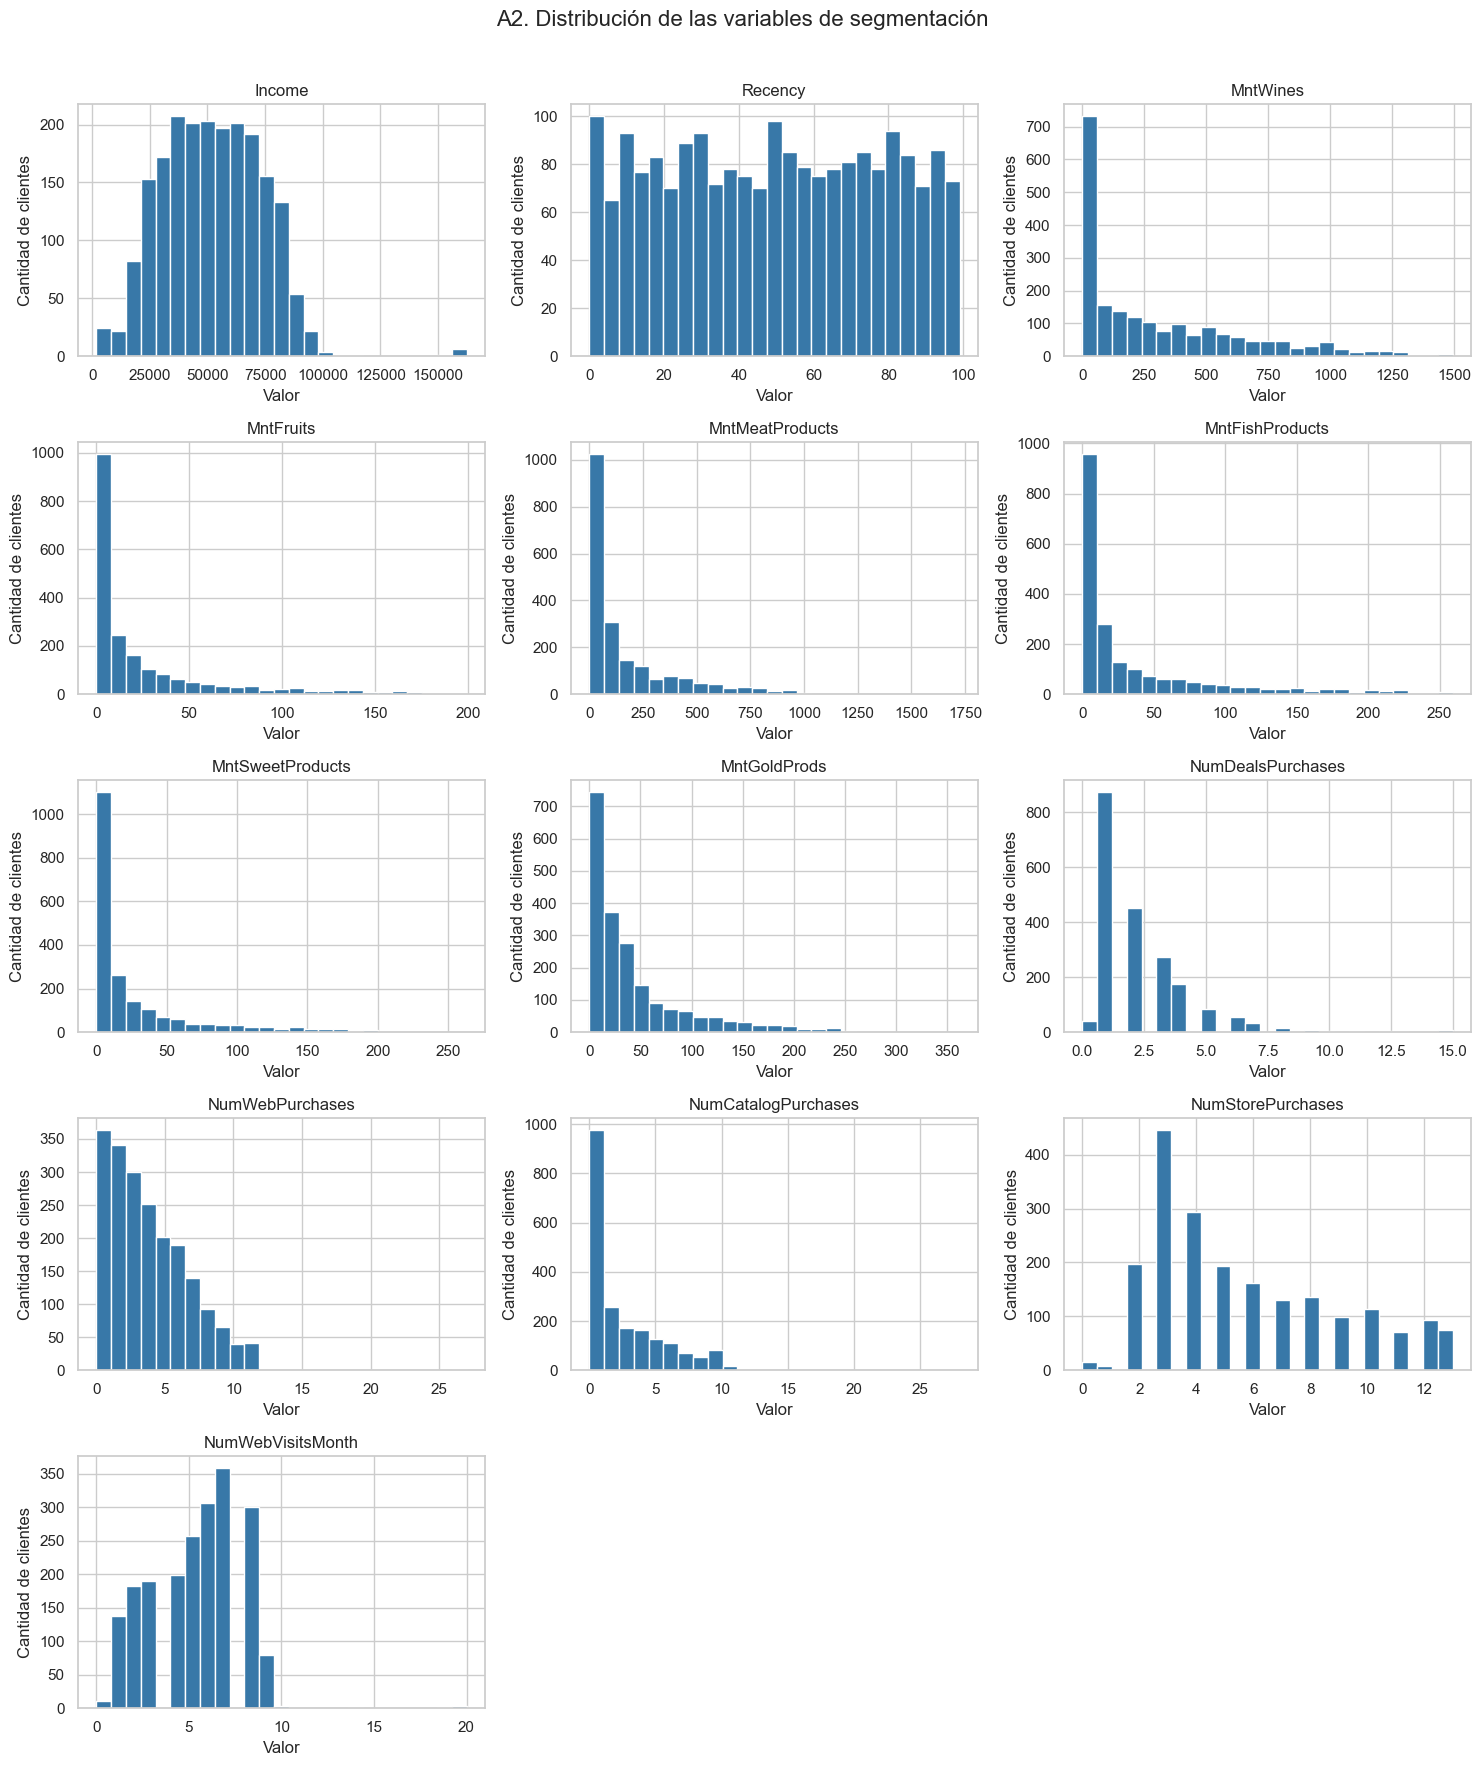

In [4]:
# Carpeta para guardar los gráficos de nuestra área
ruta_figuras = Path("reports/figures")
ruta_figuras.mkdir(parents=True, exist_ok=True)

# Histogramas: cada variable conserva su propia escala
fig, axes = plt.subplots(5, 3, figsize=(15, 18))
axes = axes.ravel()

for ax, columna in zip(axes, variables_segmentacion):
    ax.hist(
        X_original[columna],
        bins=25,
        color="#3878A8",
        edgecolor="white"
    )
    ax.set_title(columna)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Cantidad de clientes")

# Ocultar los espacios que no se utilizan
for ax in axes[len(variables_segmentacion):]:
    ax.set_visible(False)

fig.suptitle(
    "A2. Distribución de las variables de segmentación",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    ruta_figuras / "A2_01_histogramas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación de las distribuciones

Los gastos por categoría presentan asimetría hacia la derecha:
muchos clientes registran gastos bajos y una cantidad menor
presenta gastos elevados.

Las compras por web y catálogo también se concentran en cantidades
bajas. Las compras en tienda muestran una distribución más extendida.
La recencia presenta una distribución aproximadamente uniforme
entre 0 y 99 días.

Estas diferencias permiten explorar segmentos según intensidad
de compra, categorías y canales utilizados. Los histogramas por sí
solos no demuestran la existencia de grupos separados.

### 3.4 Estandarización de las variables

Aplicamos StandardScaler para que cada variable tenga media
aproximadamente cero y desviación estándar uno. Así evitamos que
las diferencias de unidades, como ingresos frente a cantidad de
compras, dominen el cálculo de distancias.

La estandarización no elimina los valores extremos ni corrige
la asimetría; esta sensibilidad se considerará como una limitación.

Utilizamos los 2.032 clientes para explorar la segmentación de
la base actual. La división 70/30 corresponde al análisis
supervisado de campañas.

Conservamos X_original para interpretar los segmentos en sus
unidades originales.

In [5]:
# Ajustar el escalador y transformar las 13 variables seleccionadas
scaler_segmentacion = StandardScaler()

X_scaled = pd.DataFrame(
    scaler_segmentacion.fit_transform(X_original),
    columns=X_original.columns,
    index=X_original.index
)

# Comprobar el resultado de la estandarización
verificacion_escalado = pd.DataFrame({
    "Media": X_scaled.mean(),
    "Desviación estándar": X_scaled.std(ddof=0)
})

print("Dimensiones de la base estandarizada:", X_scaled.shape)
display(verificacion_escalado.round(6))

Dimensiones de la base estandarizada: (2032, 13)


,Media,Desviación estándar
Income,0.0,1.0
Recency,-0.0,1.0
MntWines,-0.0,1.0
MntFruits,-0.0,1.0
MntMeatProducts,0.0,1.0
MntFishProducts,0.0,1.0
MntSweetProducts,0.0,1.0
MntGoldProds,-0.0,1.0
NumDealsPurchases,-0.0,1.0
NumWebPurchases,0.0,1.0


## 4. Reducción de dimensionalidad con PCA

PCA combina las 13 variables estandarizadas en componentes
principales que resumen su variabilidad.

Primero calculamos todos los componentes y examinamos su varianza
explicada individual y acumulada. Elegiremos el menor número de
componentes que conserve al menos el 85 % de la varianza total,
como compromiso entre reducción y conservación de información.

Este porcentaje no representa exactitud de predicción.
Posteriormente utilizaremos los dos primeros componentes
para visualizar los clientes en un gráfico.

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.17,44.17
1,PC2,11.83,56.00
2,PC3,7.72,63.72
3,PC4,7.07,70.79
4,PC5,5.35,76.14
5,PC6,4.78,80.92
6,PC7,4.07,84.99
7,PC8,3.60,88.59
8,PC9,3.11,91.71
9,PC10,2.83,94.53


Componentes seleccionados: 8
Varianza conservada: 88.59%


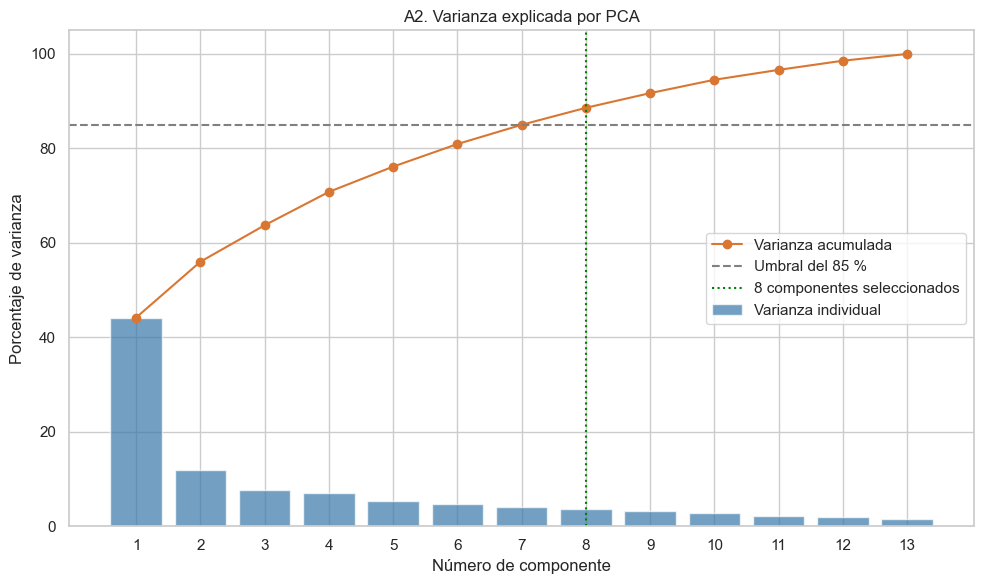

In [6]:
# Calcular todos los componentes principales
pca_completo = PCA(svd_solver="full")
pca_completo.fit(X_scaled)

varianza_individual = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

# Menor cantidad de componentes que alcanza el 85 %
UMBRAL_VARIANZA = 0.85
n_componentes = int(
    np.searchsorted(varianza_acumulada, UMBRAL_VARIANZA) + 1
)

tabla_varianza = pd.DataFrame({
    "Componente": [
        f"PC{i + 1}" for i in range(len(varianza_individual))
    ],
    "Varianza explicada (%)": varianza_individual * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

display(tabla_varianza.round(2))

print(f"Componentes seleccionados: {n_componentes}")
print(
    "Varianza conservada: "
    f"{varianza_acumulada[n_componentes - 1]:.2%}"
)

# Gráfico de varianza individual y acumulada
componentes = np.arange(1, len(varianza_individual) + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    componentes,
    varianza_individual * 100,
    color="#3878A8",
    alpha=0.7,
    label="Varianza individual"
)

ax.plot(
    componentes,
    varianza_acumulada * 100,
    marker="o",
    color="#D97732",
    label="Varianza acumulada"
)

ax.axhline(
    UMBRAL_VARIANZA * 100,
    color="gray",
    linestyle="--",
    label="Umbral del 85 %"
)

ax.axvline(
    n_componentes,
    color="green",
    linestyle=":",
    label=f"{n_componentes} componentes seleccionados"
)

ax.set(
    title="A2. Varianza explicada por PCA",
    xlabel="Número de componente",
    ylabel="Porcentaje de varianza",
    xticks=componentes,
    ylim=(0, 105)
)

ax.legend()
plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_02_varianza_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.1 Interpretación y proyección de los clientes

Los primeros ocho componentes conservan el 88,59 % de la varianza,
cumpliendo el umbral del 85 % elegido para este análisis.
Con siete componentes se conserva el 84,99 %, por debajo del umbral.

Utilizaremos los ocho componentes para el agrupamiento.
Para visualizar los clientes, mostraremos únicamente PC1 y PC2,
que explican conjuntamente el 56,00 % de la varianza.

Cada punto representa un cliente. Esta proyección es parcial
y todavía no contiene segmentos asignados.

Dimensiones de la base para agrupamiento: (2032, 8)


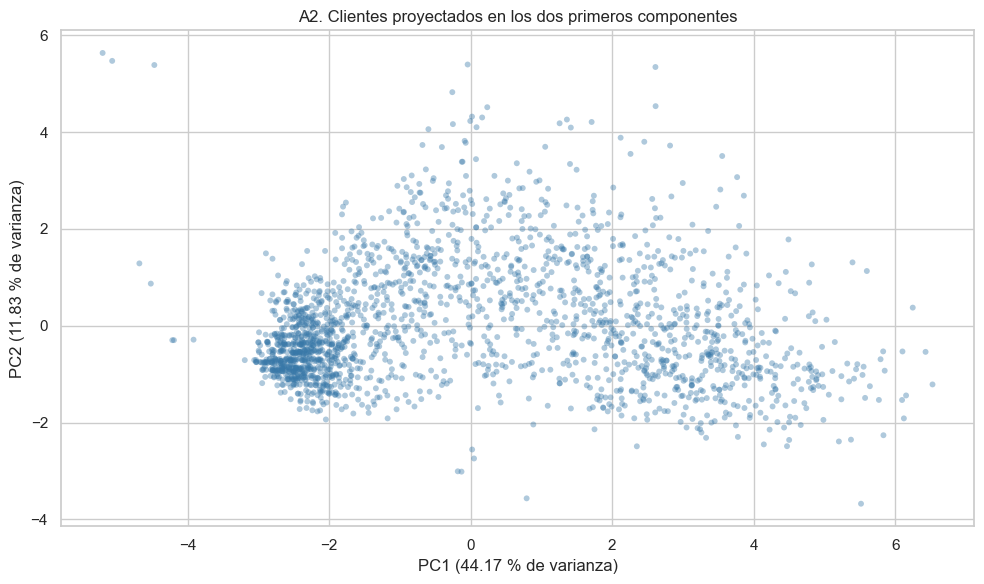

In [7]:
# Transformar las variables en los componentes seleccionados
pca_segmentacion = PCA(
    n_components=n_componentes,
    svd_solver="full"
)

X_pca = pd.DataFrame(
    pca_segmentacion.fit_transform(X_scaled),
    columns=[f"PC{i + 1}" for i in range(n_componentes)],
    index=X_scaled.index
)

print("Dimensiones de la base para agrupamiento:", X_pca.shape)

# Visualizar los dos primeros componentes
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    X_pca["PC1"],
    X_pca["PC2"],
    s=18,
    alpha=0.4,
    color="#3878A8",
    edgecolors="none"
)

porcentajes = pca_segmentacion.explained_variance_ratio_ * 100

ax.set(
    title="A2. Clientes proyectados en los dos primeros componentes",
    xlabel=f"PC1 ({porcentajes[0]:.2f} % de varianza)",
    ylabel=f"PC2 ({porcentajes[1]:.2f} % de varianza)"
)

plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_03_proyeccion_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.2 Interpretación de los componentes principales

La proyección muestra una zona de alta concentración y clientes
más dispersos, sin una separación completa entre grupos.

Para interpretar los ejes revisamos los coeficientes de las variables
en PC1 y PC2. Un coeficiente de mayor valor absoluto indica mayor
peso de esa variable en la construcción del componente.

El signo indica la dirección de la relación con el componente;
no representa una valoración positiva o negativa del cliente.

Coeficientes de las variables en PC1 y PC2:


,PC1,PC2
Income,0.355,-0.044
Recency,0.004,-0.004
MntWines,0.313,0.221
MntFruits,0.297,-0.116
MntMeatProducts,0.333,-0.127
MntFishProducts,0.306,-0.126
MntSweetProducts,0.295,-0.087
MntGoldProds,0.242,0.211
NumDealsPurchases,-0.041,0.633
NumWebPurchases,0.228,0.494



Variables con mayor peso absoluto en PC1:


,PC1
Income,0.355
NumCatalogPurchases,0.340
MntMeatProducts,0.333
MntWines,0.313
NumStorePurchases,0.311



Variables con mayor peso absoluto en PC2:


,PC2
NumDealsPurchases,0.633
NumWebPurchases,0.494
NumWebVisitsMonth,0.417
MntWines,0.221
MntGoldProds,0.211


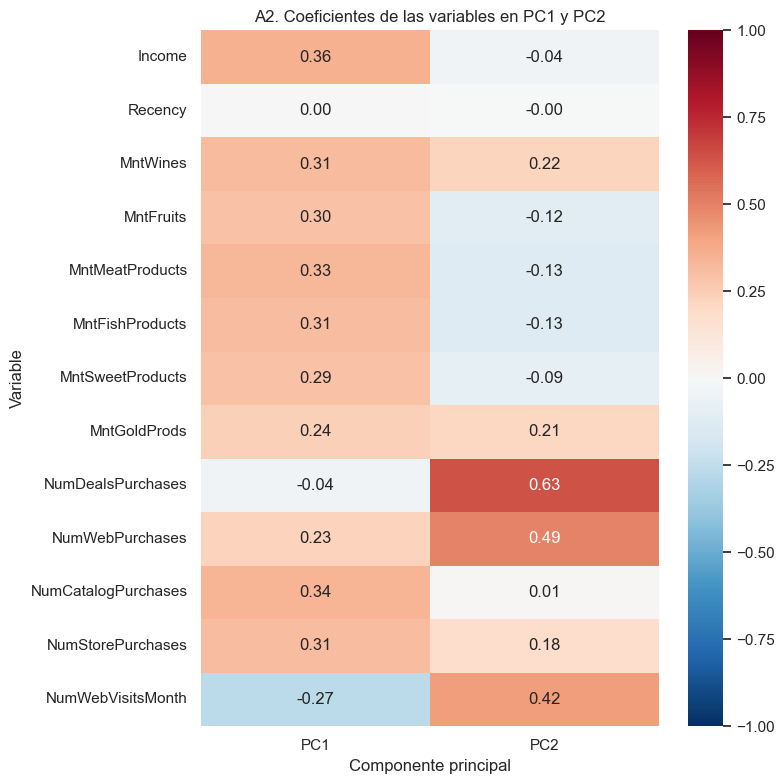

In [8]:
# Coeficientes de las variables en los componentes seleccionados
coeficientes_pca = pd.DataFrame(
    pca_segmentacion.components_.T,
    index=variables_segmentacion,
    columns=X_pca.columns
)

print("Coeficientes de las variables en PC1 y PC2:")
display(coeficientes_pca[["PC1", "PC2"]].round(3))

# Mostrar las cinco variables con mayor peso absoluto en cada eje
for componente in ["PC1", "PC2"]:
    principales = (
        coeficientes_pca[componente]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .index
    )

    print(f"\nVariables con mayor peso absoluto en {componente}:")
    display(
        coeficientes_pca.loc[principales, [componente]].round(3)
    )

# Visualizar los coeficientes de ambos componentes
plt.figure(figsize=(8, 8))

sns.heatmap(
    coeficientes_pca[["PC1", "PC2"]],
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("A2. Coeficientes de las variables en PC1 y PC2")
plt.xlabel("Componente principal")
plt.ylabel("Variable")
plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_04_coeficientes_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación de PC1 y PC2

PC1 presenta coeficientes positivos elevados en ingresos,
compras por catálogo y gastos en diferentes categorías.
Se interpreta como un eje de capacidad económica e intensidad
de consumo. Las visitas web tienen un coeficiente negativo.

PC2 está relacionado principalmente con compras con descuento,
compras web y visitas al sitio. Describe diferencias en el uso
del canal digital y las compras promocionales.

Estas interpretaciones resumen tendencias, no reglas que
se cumplan individualmente en todos los clientes.

## 5. Agrupamiento con k-means

### 5.1 Evaluación del número de grupos

Evaluamos entre 2 y 8 grupos utilizando los ocho componentes
principales seleccionados.

Para cada alternativa calculamos la silueta promedio:
valores más cercanos a 1 indican grupos más compactos y separados;
valores cercanos a 0 indican solapamiento.

También revisamos el tamaño de los grupos. La elección final
considerará la silueta y la utilidad comercial de los perfiles,
sin asumir de antemano que existen tres segmentos.

,K,Silueta,Grupo menor (%),Grupo mayor (%)
0,2,0.3854,40.1083,59.8917
1,3,0.3052,26.8209,46.1614
2,4,0.2861,13.6319,45.3248
3,5,0.1857,13.3858,24.3602
4,6,0.1866,10.8268,23.8189
5,7,0.1907,6.5945,23.6220
6,8,0.1884,0.1969,23.2283


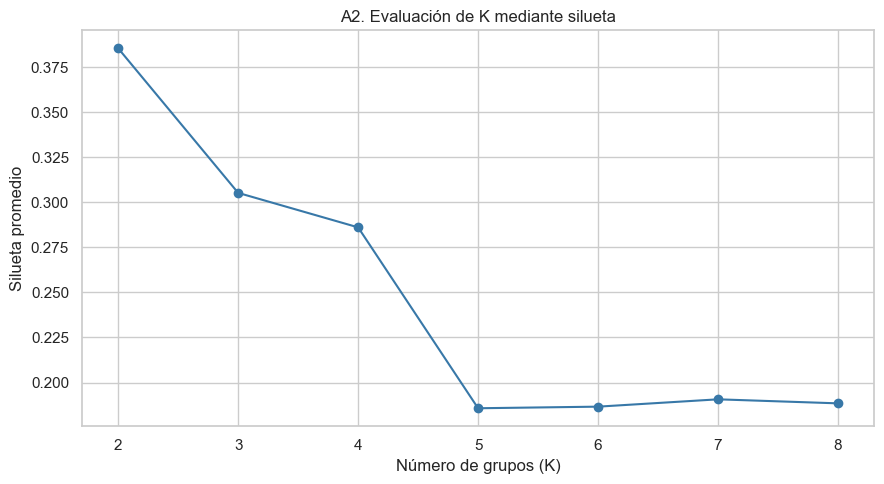

In [9]:
# Comparar diferentes cantidades de grupos
resultados_k = []
modelos_kmeans = {}

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_pca)

    silueta = silhouette_score(X_pca, etiquetas)
    tamanos = pd.Series(etiquetas).value_counts()

    resultados_k.append({
        "K": k,
        "Silueta": silueta,
        "Grupo menor (%)": tamanos.min() / len(X_pca) * 100,
        "Grupo mayor (%)": tamanos.max() / len(X_pca) * 100
    })

    modelos_kmeans[k] = modelo

tabla_k = pd.DataFrame(resultados_k)

display(tabla_k.round(4))

# Visualizar la silueta para cada K
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    tabla_k["K"],
    tabla_k["Silueta"],
    marker="o",
    color="#3878A8"
)

ax.set(
    title="A2. Evaluación de K mediante silueta",
    xlabel="Número de grupos (K)",
    ylabel="Silueta promedio",
    xticks=tabla_k["K"]
)

plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_05_silueta_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Comparación comercial de dos y tres segmentos

Entre las alternativas evaluadas, K = 2 presenta la mayor silueta
(0,3854), con grupos de aproximadamente 40 % y 60 % de la base.

K = 3 obtiene una silueta menor (0,3052). Revisaremos si el tercer
grupo aporta un perfil comercial diferenciado que justifique
la menor separación.

La elección final considerará tanto la calidad del agrupamiento
como la posibilidad de proponer acciones específicas por segmento.
La meta inicial de tres segmentos se evaluará frente a estos resultados.

In [10]:
# Variables originales para interpretar los grupos
variables_perfil = [
    "Income",
    "Total_Spent",
    "Total_Purchases",
    "Recency",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

# k-means numera los grupos de forma arbitraria y esa numeración cambia si
# cambian los datos. Fijamos K = 3 según el gasto promedio para que cada nombre
# comercial corresponda siempre al perfil correcto:
# menor gasto = grupo 1, mayor gasto = grupo 2, gasto intermedio = grupo 3.
gasto_por_etiqueta = (
    df.groupby(modelos_kmeans[3].labels_)["Total_Spent"].mean().sort_values()
)
numero_grupo_k3 = {
    gasto_por_etiqueta.index[0]: 1,
    gasto_por_etiqueta.index[2]: 2,
    gasto_por_etiqueta.index[1]: 3
}

# Comparar perfiles para K = 2 y K = 3
for k in [2, 3]:
    base_perfil = df.copy()

    # Usar las etiquetas de los modelos que ya calculamos
    if k == 3:
        base_perfil["Grupo"] = pd.Series(
            modelos_kmeans[k].labels_, index=df.index
        ).map(numero_grupo_k3)
    else:
        base_perfil["Grupo"] = modelos_kmeans[k].labels_ + 1

    perfiles = (
        base_perfil.groupby("Grupo")[variables_perfil]
        .mean()
    )

    tamanos = base_perfil.groupby("Grupo").size()

    perfiles.insert(0, "Clientes", tamanos)
    perfiles.insert(
        1, "Porcentaje (%)", tamanos / len(base_perfil) * 100
    )

    print(f"\nPERFILES COMERCIALES PARA K = {k}")
    display(perfiles.round(2).T)


PERFILES COMERCIALES PARA K = 2


Grupo,1,2
Clientes,1217.00,815.00
Porcentaje (%),59.89,40.11
Income,39082.45,71448.36
Total_Spent,188.09,1231.78
Total_Purchases,7.82,19.60
Recency,48.92,49.50
NumDealsPurchases,2.52,2.04
NumWebPurchases,2.98,5.78
NumCatalogPurchases,0.90,5.29
NumStorePurchases,3.94,8.53



PERFILES COMERCIALES PARA K = 3


Grupo,1,2,3
Clientes,938.00,545.00,549.00
Porcentaje (%),46.16,26.82,27.02
Income,35183.67,75730.34,57410.62
Total_Spent,95.45,1365.43,726.99
Total_Purchases,5.84,19.69,16.91
Recency,49.46,49.23,48.55
NumDealsPurchases,1.99,1.40,3.82
NumWebPurchases,2.09,5.33,6.33
NumCatalogPurchases,0.55,6.01,2.96
NumStorePurchases,3.21,8.35,7.63


### 5.3 Elección de K y segmentos propuestos

K = 2 obtiene la mayor silueta (0,3854) y distingue principalmente
clientes de menor y mayor intensidad de compra.

Seleccionamos K = 3 para la propuesta comercial porque permite
distinguir un perfil adicional con mayor cantidad de compras web
y compras con descuento. Los grupos tienen tamaños relevantes:
46,16 %, 26,82 % y 27,02 % de la base.

Esta elección prioriza la utilidad comercial frente a la mayor
separación de K = 2. La silueta de K = 3 es 0,3052, inferior a la
meta inicial de 0,35; por tanto, ese criterio técnico no se cumple.

Los nombres comerciales describen comportamientos observados:
- Grupo 1: Clientes de bajo consumo.
- Grupo 2: Clientes de alto gasto multicanal.
- Grupo 3: Compradores web y de promociones.

Estas etiquetas no demuestran rentabilidad, fidelidad ni respuesta
futura a las promociones. Las acciones propuestas deberán validarse
mediante una campaña piloto.

,Grupo_KMeans,Segmento,Clientes,Porcentaje (%)
0,1,Clientes de bajo consumo,938,46.16
1,2,Clientes de alto gasto multicanal,545,26.82
2,3,Compradores web y de promociones,549,27.02


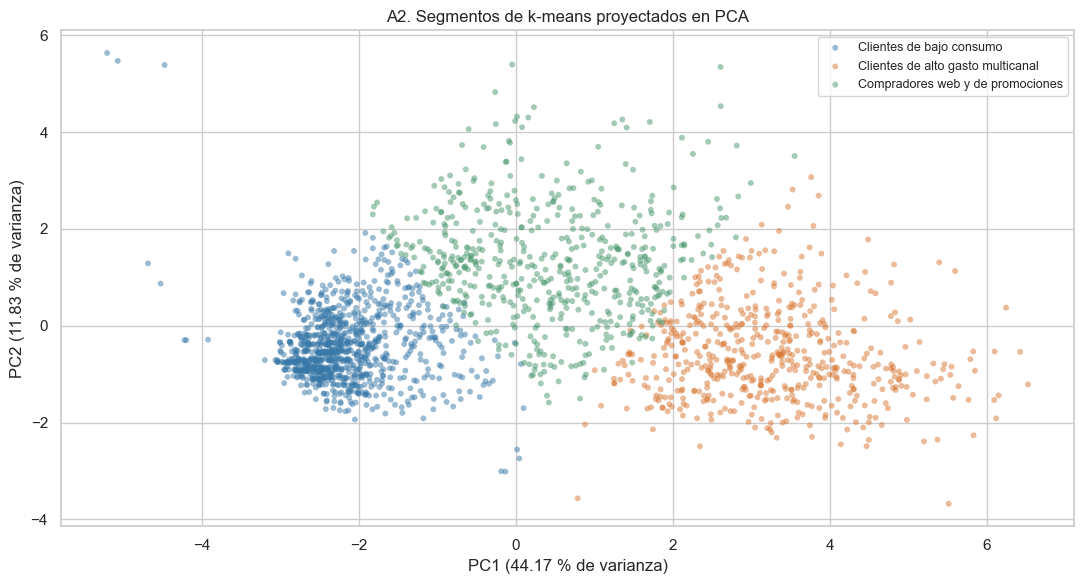

In [11]:
# Modelo elegido para la propuesta comercial
K_ELEGIDO = 3
modelo_kmeans = modelos_kmeans[K_ELEGIDO]

# Conservar los valores originales y añadir el segmento
df_segmentado = df.copy()
df_segmentado["Grupo_KMeans"] = pd.Series(
    modelo_kmeans.labels_, index=df_segmentado.index
).map(numero_grupo_k3)

nombres_segmentos = {
    1: "Clientes de bajo consumo",
    2: "Clientes de alto gasto multicanal",
    3: "Compradores web y de promociones"
}

df_segmentado["Segmento"] = (
    df_segmentado["Grupo_KMeans"].map(nombres_segmentos)
)

# Resumen de tamaños
resumen_segmentos = (
    df_segmentado.groupby(["Grupo_KMeans", "Segmento"])
    .size()
    .reset_index(name="Clientes")
)

resumen_segmentos["Porcentaje (%)"] = (
    resumen_segmentos["Clientes"] / len(df_segmentado) * 100
)

display(resumen_segmentos.round(2))

# Proyección de los grupos en PC1 y PC2
fig, ax = plt.subplots(figsize=(11, 6))

colores = ["#3878A8", "#D97732", "#47966D"]

for grupo, color in zip([1, 2, 3], colores):
    mascara = df_segmentado["Grupo_KMeans"] == grupo

    ax.scatter(
        X_pca.loc[mascara, "PC1"],
        X_pca.loc[mascara, "PC2"],
        s=18,
        alpha=0.5,
        color=color,
        label=nombres_segmentos[grupo],
        edgecolors="none"
    )

ax.set(
    title="A2. Segmentos de k-means proyectados en PCA",
    xlabel=f"PC1 ({porcentajes[0]:.2f} % de varianza)",
    ylabel=f"PC2 ({porcentajes[1]:.2f} % de varianza)"
)

ax.legend(fontsize=9)
plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_06_segmentos_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Agrupamiento jerárquico

Aplicamos clustering jerárquico con el método de Ward sobre los mismos
ocho componentes principales utilizados en k-means.

Ward une progresivamente grupos buscando minimizar el incremento de
la variación dentro de ellos. El dendrograma permite visualizar estas
uniones y explorar posibles cortes para obtener segmentos.

Para facilitar la lectura, mostramos las últimas 30 agrupaciones.
El cálculo incluye los 2032 clientes.

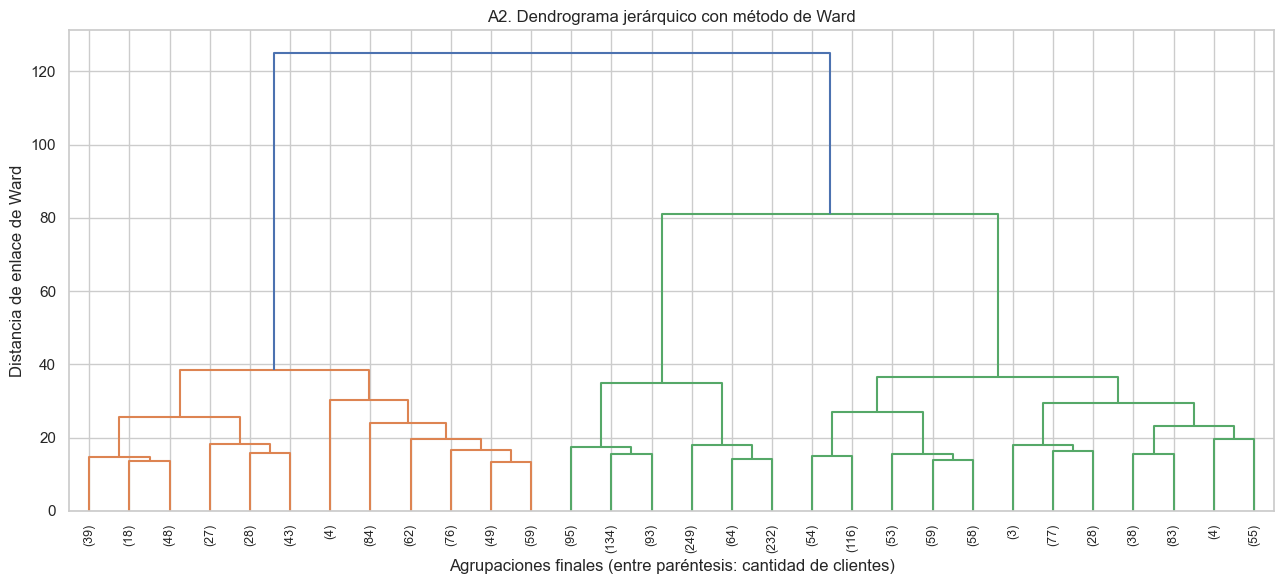

In [12]:
# Calcular las uniones jerárquicas sobre los ocho componentes
enlaces_ward = linkage(
    X_pca,
    method="ward",
    metric="euclidean"
)

# Mostrar un dendrograma resumido
fig, ax = plt.subplots(figsize=(13, 6))

dendrogram(
    enlaces_ward,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax
)

ax.set(
    title="A2. Dendrograma jerárquico con método de Ward",
    xlabel="Agrupaciones finales (entre paréntesis: cantidad de clientes)",
    ylabel="Distancia de enlace de Ward"
)

plt.tight_layout()

plt.savefig(
    ruta_figuras / "A2_07_dendrograma_ward.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.1. Comparación de Ward con k-means

El dendrograma permite explorar una solución de tres grupos mediante
un corte entre las distancias de enlace aproximadas de 38 y 81.

Comparamos esta solución con k-means usando tres grupos y los mismos
ocho componentes principales. Evaluamos la silueta promedio y el
tamaño de los grupos.

Los números asignados a los grupos son etiquetas: el grupo 1 de Ward
no necesariamente representa al grupo 1 de k-means.

In [13]:
# Obtener tres grupos mediante clustering jerárquico
modelo_ward = AgglomerativeClustering(
    n_clusters=K_ELEGIDO,
    linkage="ward"
)

etiquetas_ward = modelo_ward.fit_predict(X_pca)

df_segmentado["Grupo_Ward"] = etiquetas_ward + 1

# Comparar ambos métodos en el mismo espacio de ocho componentes
comparacion_metodos = []

for nombre, etiquetas in [
    ("K-means", modelo_kmeans.labels_),
    ("Jerárquico Ward", etiquetas_ward)
]:
    cantidades = pd.Series(etiquetas).value_counts()

    comparacion_metodos.append({
        "Método": nombre,
        "Grupos": len(cantidades),
        "Silueta": silhouette_score(X_pca, etiquetas),
        "Grupo menor (%)": cantidades.min() / len(X_pca) * 100,
        "Grupo mayor (%)": cantidades.max() / len(X_pca) * 100
    })

tabla_comparacion = pd.DataFrame(comparacion_metodos)

print("Comparación de métodos:")
display(tabla_comparacion.round(4))

print("\nCantidad de clientes por grupo de Ward:")
display(
    df_segmentado.groupby("Grupo_Ward")
    .size()
    .rename("Clientes")
    .to_frame()
)

print("\nCoincidencias entre las asignaciones de ambos métodos:")
display(
    pd.crosstab(
        df_segmentado["Grupo_KMeans"],
        df_segmentado["Grupo_Ward"],
        rownames=["Grupo K-means"],
        colnames=["Grupo Ward"]
    )
)

Comparación de métodos:


,Método,Grupos,Silueta,Grupo menor (%),Grupo mayor (%)
0,K-means,3,0.3052,26.8209,46.1614
1,Jerárquico Ward,3,0.2779,26.4272,42.6673



Cantidad de clientes por grupo de Ward:


,Clientes
Grupo_Ward,
1,537
2,628
3,867



Coincidencias entre las asignaciones de ambos métodos:


Grupo Ward,1,2,3
Grupo K-means,,,
1,0,87,851
2,494,51,0
3,43,490,16


### 6.2. Interpretación y selección del método

Para tres grupos, k-means obtuvo una silueta de 0,3052, superior
a la obtenida mediante Ward (0,2779). Ambos métodos muestran
correspondencias entre sus grupos, aunque no asignan todos los
clientes de la misma manera.

Se conserva k-means con tres grupos como propuesta comercial por
su mayor silueta frente a Ward y por los perfiles identificados:
bajo consumo, alto gasto multicanal y compradores web y de promociones.

Esta elección implica un compromiso: k-means con dos grupos alcanzó
una silueta superior (0,3854), mientras que tres grupos permiten
proponer acciones comerciales más diferenciadas.

La solución seleccionada no alcanza el objetivo inicial de silueta
de 0,35 establecido por el equipo. Por ello, se considera una
segmentación exploratoria que requiere validación comercial.

## 7. Perfiles finales de los segmentos

Describimos los segmentos mediante promedios de las variables
originales, sin estandarización. Incluimos ingresos, gasto por
categoría, compras por canal y composición familiar.

Estos promedios describen a cada grupo; no representan necesariamente
a todos sus integrantes ni demuestran la eficacia de una campaña.

In [14]:
variables_perfil_final = [
    "Income",
    "Total_Spent",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Recency",
    "Children",
    "Family_Size"
]

# Promedios en unidades originales
perfil_final = (
    df_segmentado
    .groupby("Grupo_KMeans")[variables_perfil_final]
    .mean()
)

cantidad_clientes = (
    df_segmentado.groupby("Grupo_KMeans").size()
)

perfil_final.insert(0, "Clientes", cantidad_clientes)
perfil_final.insert(
    1,
    "Porcentaje (%)",
    cantidad_clientes / len(df_segmentado) * 100
)

# Usar los nombres comerciales como encabezados
perfil_final.index = perfil_final.index.map(nombres_segmentos)
perfil_final.index.name = "Segmento"

print("Perfiles finales: promedios por segmento")
display(perfil_final.round(2).T)

Perfiles finales: promedios por segmento


Segmento,Clientes de bajo consumo,Clientes de alto gasto multicanal,Compradores web y de promociones
Clientes,938.00,545.00,549.00
Porcentaje (%),46.16,26.82,27.02
Income,35183.67,75730.34,57410.62
Total_Spent,95.45,1365.43,726.99
MntWines,42.34,593.23,463.27
MntFruits,4.66,69.18,20.91
MntMeatProducts,21.98,452.66,134.91
MntFishProducts,6.79,100.04,27.92
MntSweetProducts,4.93,72.14,20.89
MntGoldProds,14.75,78.17,59.09


### 7.1. Interpretación comercial y acciones propuestas

#### Segmento 1: Clientes de bajo consumo

Incluye 938 clientes (46,16 %). Presenta el menor ingreso promedio
(35 183,67), el menor gasto total promedio (95,45) y el menor número
promedio de compras (5,84).

Registra 6,41 visitas web mensuales en promedio, pero pocas compras
web (2,09). Estas variables corresponden a períodos distintos, por
lo que su cociente no debe interpretarse como tasa de conversión.

**Acción propuesta:** probar ofertas de entrada y paquetes de precio
accesible, junto con una revisión de posibles dificultades de compra
en la web.

**Objetivo:** aumentar la proporción de clientes que compra y el gasto
por cliente, controlando el costo de los incentivos.

#### Segmento 2: Clientes de alto gasto multicanal

Incluye 545 clientes (26,82 %). Tiene el mayor ingreso promedio
(75 730,34), el mayor gasto total promedio (1365,43) y el mayor número
promedio de compras (19,69).

Destaca por sus compras en tienda y catálogo. Las categorías con
mayor gasto promedio son vinos (593,23) y productos cárnicos (452,66).

**Acción propuesta:** probar recomendaciones complementarias de
productos y beneficios de fidelización en tienda, catálogo y web.

**Objetivo:** mantener la actividad de compra y evaluar oportunidades
de venta cruzada. El alto gasto observado no demuestra por sí mismo
mayor rentabilidad ni fidelidad.

#### Segmento 3: Compradores web y de promociones

Incluye 549 clientes (27,02 %). Presenta un gasto total promedio de
726,99 y 16,91 compras en promedio.

Registra el mayor número promedio de compras web (6,33) y de compras
con promociones (3,82). También compra en tienda, por lo que no es
un segmento exclusivamente digital.

**Acción propuesta:** probar campañas web con ofertas selectivas y
recomendaciones basadas en las categorías de mayor consumo.

**Objetivo:** incrementar las compras y el gasto por cliente,
verificando que los descuentos no reduzcan el margen comercial.

#### Alcance de las propuestas

Las acciones son hipótesis comerciales derivadas de los perfiles;
su eficacia todavía no ha sido comprobada.

Se propone evaluarlas mediante un piloto con asignación aleatoria
a tratamiento y control dentro de cada segmento, usando el mismo
período de observación.

Los importes conservan las unidades monetarias del dataset original;
no deben presentarse como bolivianos sin una conversión documentada.

## 8. Propuesta de implementación y monitoreo

### 8.1. Uso de la segmentación

La segmentación se propone como apoyo para diseñar campañas
diferenciadas en RetailMarket Santa Cruz. Su aplicación requiere
validación mediante un piloto comercial.

El responsable de análisis prepararía las asignaciones y los perfiles.
Marketing diseñaría las campañas y la gerencia comercial aprobaría
el presupuesto y evaluaría los resultados.

Para asignar nuevos clientes se deben mantener las mismas 13 variables,
su orden, unidades y períodos de medición. Se aplicarían el escalador
y el PCA ya ajustados, y posteriormente el modelo k-means mediante
predict. No se deben volver a ajustar estos modelos en cada asignación.

En una implementación real se necesitaría un identificador estable
del cliente para relacionar el segmento con el sistema comercial.
El archivo procesado utilizado en este análisis no conserva ese ID;
el índice de una fila no debe interpretarse como identificador comercial.

### 8.2. Piloto comercial propuesto

Se propone un piloto inicial de ocho semanas, sujeto a revisión
del tamaño de muestra y del ciclo de compra.

Dentro de cada segmento, los clientes elegibles se asignarían
aleatoriamente a dos grupos:

- Tratamiento: recibiría la acción comercial propuesta.
- Control: mantendría la atención habitual, sin esa acción adicional.

Ambos grupos se observarían durante el mismo período. Se registrarían
las compras, los ingresos, los descuentos y los costos de campaña.

La ampliación de las campañas dependería de la evidencia obtenida,
considerando la incertidumbre de los resultados y el beneficio
económico después de costos.

### 8.3. Indicadores de seguimiento comercial

| Indicador | Cálculo | Frecuencia |
|---|---|---|
| Proporción de compradores | Clientes con al menos una compra / clientes asignados al grupo × 100 | Semanal |
| Ingreso por cliente | Ingresos del período / clientes asignados al grupo | Semanal |
| Compras por cliente | Número de compras del período / clientes asignados al grupo | Semanal |
| Efecto incremental en ingreso por cliente | Ingreso por cliente de tratamiento − ingreso por cliente de control | Al finalizar el piloto |
| Contribución neta por cliente | (Ingresos netos de descuentos − costo de productos − costo de campaña) / clientes asignados al grupo | Al finalizar el piloto |

Los indicadores se calcularían por segmento y por grupo experimental,
incluyendo a los clientes que no compraron.

El dataset actual permite describir comportamientos históricos,
pero no contiene los resultados de este piloto ni todos los costos
necesarios para calcular la contribución neta.

### 8.4. Monitoreo de los datos y del modelo

| Aspecto | Revisión propuesta | Acción |
|---|---|---|
| Calidad de datos | Verificar columnas, unidades, valores faltantes y duplicados en cada carga | Corregir la carga antes de asignar segmentos |
| Tamaño de segmentos | Comparar mensualmente sus porcentajes con la distribución inicial | Investigar cambios relevantes |
| Perfil de segmentos | Comparar mensualmente ingreso, gasto y compras por canal | Revisar si los nombres y las acciones siguen siendo adecuados |
| Separación de grupos | Recalcular la silueta en datos nuevos comparables cuando existan al menos dos grupos representados | Investigar deterioros frente al valor inicial de 0,3052 |
| Resultado comercial | Comparar tratamiento y control durante el piloto | Ajustar, ampliar o detener la acción según la evidencia |

Como alerta inicial, se propone revisar cambios superiores a
10 puntos porcentuales en el tamaño de un segmento o caídas de
silueta superiores a 0,05 respecto de la referencia inicial.
Son umbrales operativos propuestos, pendientes de validación.

Una alerta no implica reentrenar automáticamente: primero se deben
descartar errores de carga, cambios de período y efectos estacionales.

Si se reentrena el modelo, se deben comparar los nuevos perfiles con
los anteriores antes de reutilizar los nombres comerciales, porque
los números de los grupos pueden cambiar.

### 8.5. Limitaciones para la implementación

La empresa del caso es hipotética y los datos públicos no demuestran
que los mismos perfiles existan en clientes de Santa Cruz.

La segmentación es exploratoria: la solución de tres grupos no
alcanzó la meta inicial de silueta de 0,35 del equipo. Además,
la estandarización no elimina la asimetría ni la influencia de
valores extremos.

Antes de una aplicación real, se requieren datos locales comparables,
identificación de clientes y validación comercial.

## 9. Exportación de resultados

Guardamos la base con las asignaciones de segmentos, los perfiles
comerciales y las tablas de evaluación.

Los archivos se generan mediante rutas relativas para facilitar
la reproducción del análisis. La base exportada conserva el orden
del archivo de entrada, pero no contiene un identificador comercial
del cliente.

In [15]:
# Carpetas de salida
ruta_resultados = Path("data/processed")
ruta_tablas = Path("reports/tables")

ruta_resultados.mkdir(parents=True, exist_ok=True)
ruta_tablas.mkdir(parents=True, exist_ok=True)

# Base original con segmentos de k-means y grupos de Ward
df_segmentado.to_csv(
    ruta_resultados / "A2_clientes_segmentados.csv",
    index=False,
    encoding="utf-8-sig"
)

# Perfiles en unidades originales
perfil_final.to_csv(
    ruta_tablas / "A2_perfiles_segmentos.csv",
    index=True,
    encoding="utf-8-sig"
)

# Evaluación de diferentes cantidades de grupos
tabla_k.to_csv(
    ruta_tablas / "A2_evaluacion_kmeans.csv",
    index=False,
    encoding="utf-8-sig"
)

# Comparación entre k-means y Ward
tabla_comparacion.to_csv(
    ruta_tablas / "A2_comparacion_metodos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Varianza explicada por PCA
tabla_varianza.to_csv(
    ruta_tablas / "A2_varianza_PCA.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos guardados correctamente:")
print(ruta_resultados / "A2_clientes_segmentados.csv")

for nombre in [
    "A2_perfiles_segmentos.csv",
    "A2_evaluacion_kmeans.csv",
    "A2_comparacion_metodos.csv",
    "A2_varianza_PCA.csv"
]:
    print(ruta_tablas / nombre)

print("\nClientes exportados:", len(df_segmentado))

Archivos guardados correctamente:
data\processed\A2_clientes_segmentados.csv
reports\tables\A2_perfiles_segmentos.csv
reports\tables\A2_evaluacion_kmeans.csv
reports\tables\A2_comparacion_metodos.csv
reports\tables\A2_varianza_PCA.csv

Clientes exportados: 2032


## 10. Conclusiones del área A2

Se analizaron 2032 clientes mediante 13 variables de ingresos,
consumo y comportamiento de compra. Las variables se estandarizaron
antes de aplicar PCA y los métodos de agrupamiento.

PCA permitió reducir las 13 variables a ocho componentes,
conservando el 88,59 % de la varianza. Los dos primeros componentes,
utilizados en las visualizaciones, representan el 56,00 %.

Entre los valores de K evaluados, k-means con dos grupos obtuvo
la mayor silueta (0,3854). Se seleccionaron tres grupos como propuesta
comercial exploratoria porque permiten distinguir perfiles para
acciones diferenciadas:

- Clientes de bajo consumo: 938 clientes (46,16 %).
- Clientes de alto gasto multicanal: 545 clientes (26,82 %).
- Compradores web y de promociones: 549 clientes (27,02 %).

Para tres grupos, k-means obtuvo una silueta de 0,3052, superior
a Ward (0,2779). Sin embargo, la solución seleccionada no alcanzó
la meta inicial de 0,35 establecida por el equipo.

Los perfiles permiten proponer acciones comerciales, pero no
demuestran que estas incrementen las ventas o la rentabilidad.
Se plantea validarlas mediante un piloto con tratamiento y control
dentro de cada segmento.

La aplicación real requiere datos locales comparables, un identificador
estable del cliente y seguimiento de la calidad de datos, los perfiles
y los resultados comerciales.

## 11. Entorno de ejecución

Registramos la versión de Python y de las librerías utilizadas
en el área A2. El notebook se comprobó reiniciando el kernel y
ejecutando todas las celdas en orden, sin errores.

In [16]:
import platform
from importlib.metadata import version

paquetes_a2 = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "ipython",
    "ipykernel"
]

lineas_entorno = [
    f"Python: {platform.python_version()}",
    "",
    "Librerías:"
]

lineas_entorno.extend(
    f"{paquete}=={version(paquete)}"
    for paquete in paquetes_a2
)

texto_entorno = "\n".join(lineas_entorno)

ruta_entorno = Path("reports/A2_entorno.txt")
ruta_entorno.parent.mkdir(parents=True, exist_ok=True)
ruta_entorno.write_text(texto_entorno, encoding="utf-8")

print(texto_entorno)
print(f"\nRegistro guardado en: {ruta_entorno}")

Python: 3.12.6

Librerías:
numpy==2.4.1
pandas==3.0.0
matplotlib==3.10.8
seaborn==0.13.2
scikit-learn==1.8.0
scipy==1.17.0
ipython==9.9.0
ipykernel==6.31.0

Registro guardado en: reports\A2_entorno.txt
